# 2. Laying curve: planning a flock and forecasting a running flock

**Author:** Mahdi Dadgar

Two questions:

1. **Planning.** Before a flock starts laying, what laying curve can I expect from its strain, house, pullet weight,
   lighting programme and planned diets?
2. **Forecasting.** For a flock in lay, what will production be over the next 12 weeks, given its records so far?

All scores are on 11 farms held out from training, so they measure performance on farms the models never saw.
The numbers come from `python -m src.compare_models` and `python -m src.train`.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import FIGURES_DIR, FLOCKS_FILE, QUALITY_FILE, REPORTS_DIR, TRUTH_DIR, WEEKLY_FILE

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 10})
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
GREEN, GREY, BLUE, ORANGE = "#2E7D32", "#757575", "#1565C0", "#E65100"
STRAIN_COL = {"Lohmann Brown-Classic": ORANGE, "Hy-Line W-80": BLUE}
pd.set_option("display.width", 140)
import joblib
from src.curves import fit_yang, yang, PARAMS
from src.features import FEATURES, weekly_training_frame
from src.modeling import split_farms, make_xgb
flocks = pd.read_csv(FLOCKS_FILE); weekly = pd.read_csv(WEEKLY_FILE)
train_farms, test_farms = split_farms(flocks)
print(len(train_farms), "training farms,", len(test_farms), "held-out farms")

41 training farms, 11 held-out farms


## The Yang laying curve

Yang, Wu and McMillan (1989) describe a laying curve with four parameters:

$$y(t) = \frac{a\,e^{-bt}}{1 + e^{-c(t-d)}}$$

*a* sets the scale, *b* the rate of decline after peak (persistency), *c* how uniform the onset of lay is, and *d* the mean
age at sexual maturity. I fitted it to every flock.

In [2]:
fits = pd.read_csv(REPORTS_DIR / "yang_fits.csv").merge(flocks[["flock_id", "strain", "housing"]], on="flock_id")
print(f"Median fit RMSE: {fits.fit_rmse.median():.2f} percentage points")
fits.groupby(["strain", "housing"])[["a", "b", "c", "d"]].median().round(4)

Median fit RMSE: 2.76 percentage points


a       b       c        d
strain                housing                                         
Hy-Line W-80          barn            99.9684  0.0023  1.2823  20.4082
                      enriched cage   97.9437  0.0022  1.3545  20.4261
                      free range      97.0291  0.0023  1.3117  20.5192
Lohmann Brown-Classic barn           107.4415  0.0050  0.7773  21.1228
                      enriched cage  107.7942  0.0048  0.7886  21.2033
                      free range     107.0931  0.0054  0.7938  21.1002

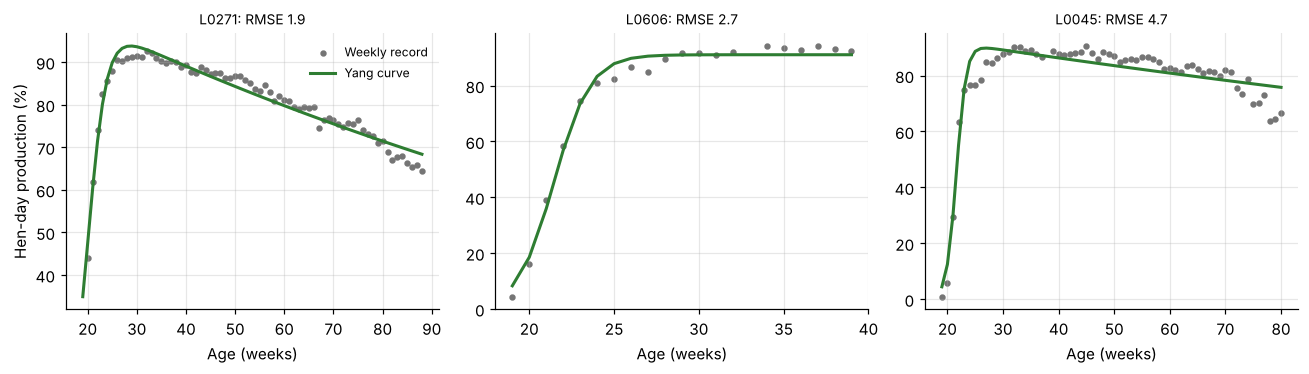

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
ex = fits.sort_values("fit_rmse").iloc[[50, 300, 590]]
for a, r in zip(ax, ex.itertuples()):
    g = weekly[weekly.flock_id == r.flock_id]
    a.scatter(g.age_wk, g.hen_day_pct, s=10, color=GREY, label="Weekly record")
    t = np.arange(19, g.age_wk.max() + 1)
    a.plot(t, yang(t, r.a, r.b, r.c, r.d), color=GREEN, lw=2, label="Yang curve")
    a.set_title(f"{r.flock_id}: RMSE {r.fit_rmse:.1f}", fontsize=9); a.set_xlabel("Age (weeks)")
ax[0].set_ylabel("Hen-day production (%)"); ax[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIGURES_DIR / "02_yang_fits.png", bbox_inches="tight"); plt.show()

The curve fits most flocks well. It cannot follow a disease dip (right panel), which is why I use it as one candidate
among several and not as the main model.

## Planning model

Candidates for weekly hen-day production, all using only what is known before lay:

In [4]:
comp = pd.read_csv(REPORTS_DIR / "planning_model_comparison.csv")
comp[comp.target == "hen_day_pct"].drop(columns="target").round(3)

,model,rmse,mae,r2,response_error
0,Breed standard,9.007,6.906,0.628,NaN
1,Training average by strain and age,6.043,4.012,0.832,NaN
2,"Ridge, broken-line features",5.658,3.563,0.853,0.501
3,"XGBoost, monotonic",4.603,3.282,0.903,0.621
4,"XGBoost, unconstrained",4.518,3.228,0.906,0.527
20,"Yang curve, parameters from flock plan",4.900,3.581,0.890,NaN


In [5]:
pd.read_csv(REPORTS_DIR / "eggs_to_72_weeks.csv").round(1)

,model,mae_eggs,bias_eggs,n_flocks
0,Breed standard,24.1,24.1,118
1,Training average by strain and age,11.3,4.8,118
2,"Ridge, broken-line features",8.8,4.6,118
3,"XGBoost, monotonic",9.3,5.7,118
4,"XGBoost, unconstrained",8.8,4.7,118
5,"Yang curve, parameters from flock plan",8.7,4.6,118


Two baselines matter here. The breed standard overestimates field flocks by 24 eggs per hen to 72 weeks. The average of the
training flocks of the same strain is much better (11 eggs off). The models bring the error down to about 9 eggs, out of
roughly 320.

What is left is mostly the farm itself. Every held-out farm has its own level that no plan can predict, which shows in the
bias of about +5 eggs: the held-out farms happen to be slightly poorer than average. That is the reason for the in-cycle
forecast below.

I chose the monotonic XGBoost model for hen-day production. It is the most accurate week by week, and every diet effect has
the right direction. The unconstrained version is slightly more accurate but predicts almost no effect of available
phosphorus. The two-stage Yang model is nearly as good and easier to explain; I use the Yang curve to summarise each
prediction in the app.

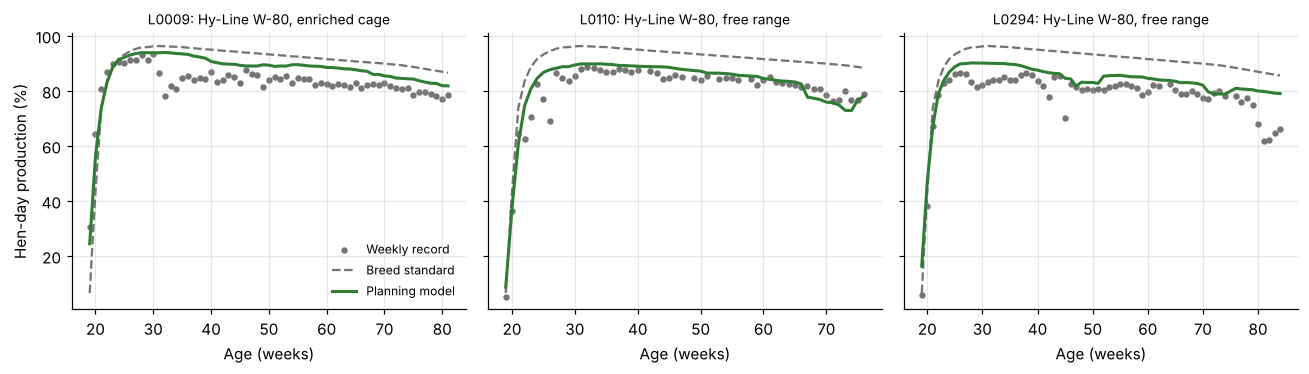

In [6]:
W = weekly_training_frame(flocks, weekly).dropna(subset=["hen_day_pct"])
tr = W[W.farm_id.isin(train_farms)]
m = make_xgb("hen_day_pct").fit(tr[FEATURES["hen_day_pct"]], tr["hen_day_pct"])
te = W[W.farm_id.isin(test_farms)].copy()
te["pred"] = m.predict(te[FEATURES["hen_day_pct"]])
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for a, fid in zip(ax, te.flock_id.drop_duplicates().iloc[[3, 25, 60]]):
    g = te[te.flock_id == fid]
    fl = flocks.set_index("flock_id").loc[fid]
    a.scatter(g.age_wk, g.hen_day_pct, s=10, color=GREY, label="Weekly record")
    a.plot(g.age_wk, g.std_hd, color=GREY, ls="--", label="Breed standard")
    a.plot(g.age_wk, g.pred, color=GREEN, lw=2, label="Planning model")
    a.set_title(f"{fid}: {fl.strain}, {fl.housing}", fontsize=9); a.set_xlabel("Age (weeks)")
ax[0].set_ylabel("Hen-day production (%)"); ax[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIGURES_DIR / "02_planning_examples.png", bbox_inches="tight"); plt.show()

### What drives the prediction

SHAP values for the planning model on the held-out farms. The breed standard and age carry the shape of the curve. After
that come free-range housing, expected house temperature, the age at light stimulation, pullet weight and the accumulated
amino acid shortfall.

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


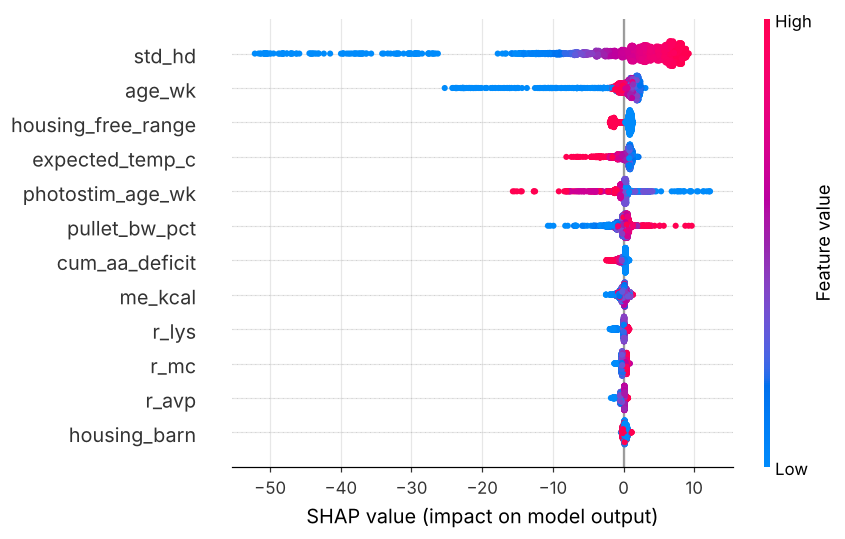

In [7]:
import shap
sample = te.sample(3000, random_state=1)
explainer = shap.TreeExplainer(m)
sv = explainer.shap_values(sample[FEATURES["hen_day_pct"]])
shap.summary_plot(sv, sample[FEATURES["hen_day_pct"]], show=False, max_display=12, plot_size=(8, 5))
plt.tight_layout(); plt.savefig(FIGURES_DIR / "02_shap_hen_day.png", bbox_inches="tight"); plt.show()

### Is the diet response right?

A model can predict flocks well and still get the effect of a diet change wrong, because diets in field data move together.
Here I can check it: the true response of the synthetic data is known (`src/truth.py`). For 60 held-out flocks I changed the
diet in all phases and compared the predicted change in eggs per hen to 72 weeks with the true change.

In [8]:
resp = pd.read_csv(REPORTS_DIR / "diet_response_check.csv")
hd = resp[resp.target == "hen_day_pct"].pivot(index="scenario", columns="model", values="mean_change")
hd = hd.loc[["Amino acids -10 %", "Amino acids -5 %", "Amino acids +5 %", "Available P -15 %", "Calcium -10 %"]]
hd.round(2)

model,"Ridge, broken-line features",Truth,"XGBoost, monotonic","XGBoost, unconstrained"
scenario,,,,
Amino acids -10 %,-7.99,-9.75,-11.21,-9.32
Amino acids -5 %,-3.83,-4.22,-4.94,-3.97
Amino acids +5 %,3.27,2.86,3.48,2.13
Available P -15 %,-2.04,-3.15,-5.09,-0.67
Calcium -10 %,0.00,-0.85,0.00,0.00


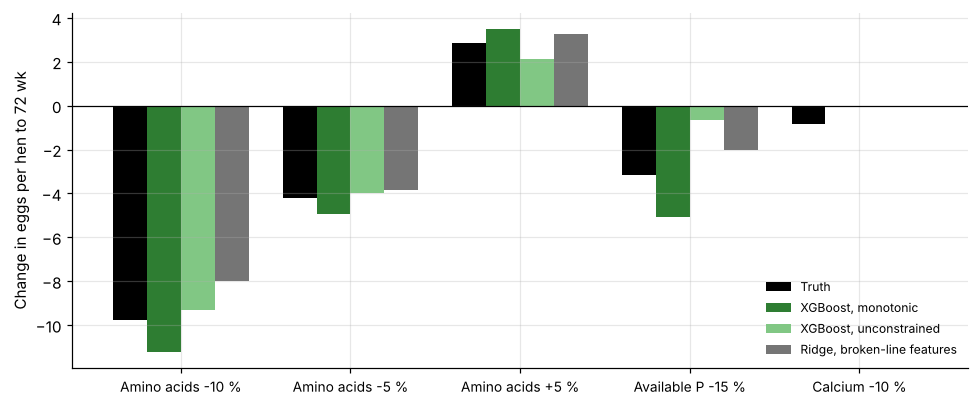

In [9]:
cols = ["Truth", "XGBoost, monotonic", "XGBoost, unconstrained", "Ridge, broken-line features"]
colors = ["black", GREEN, "#81C784", GREY]
x = np.arange(len(hd)); wdt = 0.2
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, (c, col) in enumerate(zip(cols, colors)):
    ax.bar(x + (i - 1.5) * wdt, hd[c], wdt, label=c, color=col)
ax.set_xticks(x, hd.index, fontsize=9); ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Change in eggs per hen to 72 wk"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIGURES_DIR / "02_diet_response.png", bbox_inches="tight"); plt.show()

The chosen model gets every direction right but overstates the losses: about 11 eggs for a 10 % amino acid cut against a true
10, and 5 eggs for a 15 % phosphorus cut against a true 3. Calcium is not an input of this model on purpose. In the
data, calcium supply moves together with amino acid supply because both depend on the feed intake the nutritionist assumed,
and an earlier version predicted a loss of about 3 eggs from a 10 % calcium cut against a true loss of less than one. In the
normal range calcium acts on the shell, which the shell model covers.

## In-cycle forecast

At a cutoff age (every 4 weeks from 24 to 80) the model sees the records so far and forecasts 1 to 12 weeks ahead. It predicts
the deviation from the breed standard from the recent deviation and its trend, feed intake, mortality, egg weight and house
temperature, plus the planned diet and normal temperature for the coming weeks.

In [10]:
fh = pd.read_csv(REPORTS_DIR / "forecast_by_horizon.csv")
num = fh[fh.horizon.astype(str).str.isnumeric()].assign(horizon=lambda d: d.horizon.astype(int))
table = num.pivot(index="horizon", columns="method", values="mae")
table.round(2)

method,Breed standard,Last week carried forward,Planning model (no records),Standard x recent ratio,XGBoost forecast,Yang curve refitted to weeks so far
horizon,,,,,,
1,6.40,1.50,3.07,2.01,1.52,2.32
2,6.40,2.03,3.08,2.28,1.78,2.51
3,6.44,2.46,3.03,2.51,1.91,2.77
4,6.44,2.65,3.06,2.59,1.96,2.89
5,6.47,2.95,3.05,2.72,2.05,3.07
6,6.49,3.20,3.08,2.87,2.13,3.29
7,6.55,3.53,3.04,3.05,2.17,3.56
8,6.55,3.69,3.08,3.12,2.18,3.69
9,6.57,3.94,3.07,3.18,2.23,3.86


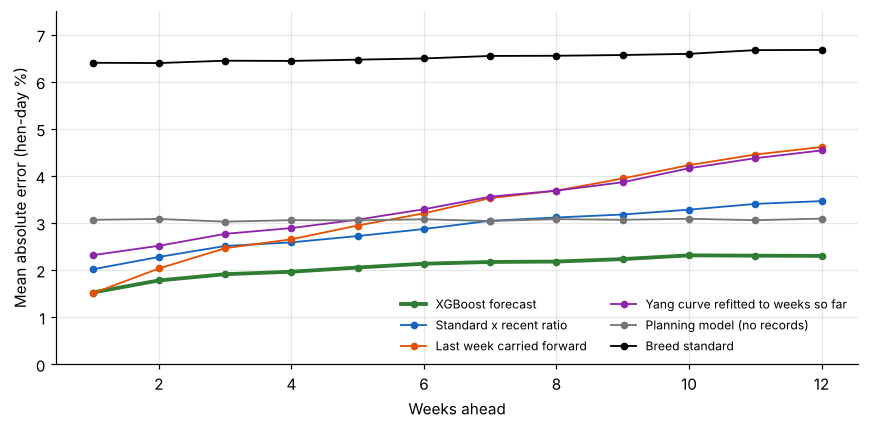

horizon,all (cutoff >= 32 wk),"all, during a disease episode"
method,,
Breed standard,6.72,9.98
Last week carried forward,3.01,3.22
Planning model (no records),3.06,4.59
Standard x recent ratio,2.26,3.44
XGBoost forecast,2.01,2.43
Yang curve refitted to weeks so far,3.37,4.53


In [11]:
order = ["XGBoost forecast", "Standard x recent ratio", "Last week carried forward",
         "Yang curve refitted to weeks so far", "Planning model (no records)", "Breed standard"]
colors = [GREEN, BLUE, ORANGE, "#8E24AA", GREY, "black"]
fig, ax = plt.subplots(figsize=(8, 4))
for mth, c in zip(order, colors):
    ax.plot(table.index, table[mth], marker="o", ms=4, color=c, label=mth, lw=2.5 if mth.startswith("XGB") else 1.2)
ax.set_xlabel("Weeks ahead"); ax.set_ylabel("Mean absolute error (hen-day %)")
ax.legend(frameon=False, fontsize=8, ncol=2); ax.set_ylim(0, 7.5)
plt.tight_layout(); plt.savefig(FIGURES_DIR / "02_forecast_by_horizon.png", bbox_inches="tight"); plt.show()
fh[~fh.horizon.astype(str).str.isnumeric()].pivot(index="method", columns="horizon", values="mae").round(2)

One week ahead, carrying last week forward is as good as the model. From two weeks on, the model is clearly better than every
simple rule, and its error grows slowly: 1.5 points one week ahead, 2.3 points twelve weeks ahead. The gap is largest during a
disease episode (2.4 against 3.2 to 4.5 for the rules), because the model has learned how flocks usually recover.

The 90 % intervals come from out-of-fold errors per horizon on the training farms. On the held-out farms they cover
89.5 % of the outcomes.

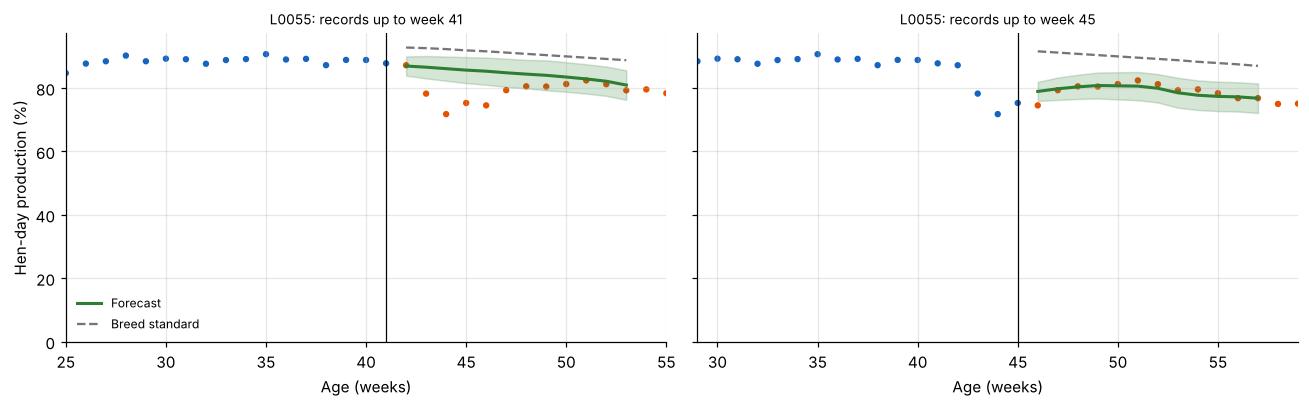

Blue: records the model saw. Orange: what happened next.


In [12]:
from src.predict import get_predictor
P = get_predictor()
events = pd.read_csv(TRUTH_DIR / "disease_events.csv")
test_ids = set(flocks[flocks.farm_id.isin(test_farms)].flock_id)
ev = events[events.flock_id.isin(test_ids) & (events.depth > 0.08) & events.start_wk.between(36, 60)].iloc[0]
fl = flocks.set_index("flock_id").loc[ev.flock_id].to_dict(); fl["flock_id"] = ev.flock_id
rec = weekly[weekly.flock_id == ev.flock_id]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for a, cut in zip(ax, [ev.start_wk - 2, ev.start_wk + 2]):
    f = P.forecast(fl, rec[rec.age_wk <= cut])["forecast"]
    a.scatter(rec.age_wk, rec.hen_day_pct, s=10, color=np.where(rec.age_wk <= cut, BLUE, ORANGE))
    a.fill_between(f.age_wk, f.lower, f.upper, color=GREEN, alpha=0.2)
    a.plot(f.age_wk, f.hen_day_pct, color=GREEN, lw=2, label="Forecast")
    a.plot(f.age_wk, f.breed_standard, color=GREY, ls="--", label="Breed standard")
    a.axvline(cut, color="black", lw=0.8)
    a.set_title(f"{ev.flock_id}: records up to week {cut}", fontsize=9); a.set_xlabel("Age (weeks)")
    a.set_xlim(cut - 16, cut + 14)
ax[0].set_ylabel("Hen-day production (%)"); ax[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIGURES_DIR / "02_forecast_example.png", bbox_inches="tight"); plt.show()
print("Blue: records the model saw. Orange: what happened next.")

Left: before the episode, the model cannot know it is coming. Right: two weeks into the episode, it forecasts a recovery
that leaves the flock below its earlier level, which is what usually happens.